# Milestone 1 — Text → Embedding Baseline (Hemanth)

**Dataset:** COCO 2017 Captions (`val2017`) · **Text encoders:** CLIP ViT-L/14 (the Stable Diffusion v1.5
conditioning encoder) and BERT-base · **Stack:** PyTorch + 🤗 `diffusers` + 🤗 `transformers`

This notebook covers the four Milestone 1 requirements:

| Requirement | Where |
|---|---|
| Choose a dataset | §2 — COCO 2017 val, 5,000 images × ~5 captions |
| Clean and preprocess 1k–5k image–caption pairs | §3–§5 — **2,000** curated pairs, images at 512×512 |
| Environment (PyTorch + Diffusers + CLIP) | §1 — `uv sync`; runs on CUDA, Apple-silicon MPS or CPU |
| Baseline text → embedding pipeline | §6–§9 — CLIP + BERT embeddings, stored and sanity-checked |

**How this differs from the team notebook (`milestone_1.ipynb`)**

- **CLIP-scored curation.** Each image keeps the *one* caption that CLIP ViT-B/32 rates as best matching it,
  and the 10 % worst-aligned images are dropped before sampling — so the subset favours captions that actually
  describe their picture.
- **Token-aware filtering.** Captions are filtered on their real CLIP token count (the 77-token limit), not just
  on characters.
- **Independent evaluation.** Retrieval checks use ViT-L/14, a *different* CLIP model from the one used for
  curation, so the subset is not graded by the model that picked it.
- **Training-ready output.** §10 wraps everything in a PyTorch `Dataset` that Milestone 2 can import directly.

All artefacts go to `data/processed/hemanth/` and `outputs/hemanth/` (both git-ignored), so this notebook never
overwrites the team notebook's files.

---
## 1. Environment

Dependencies are pinned in `pyproject.toml` / `uv.lock` and installed with `uv sync`. On macOS the lockfile
resolves the standard PyPI PyTorch build (CPU + MPS); on Linux/Windows it resolves the CUDA 12.8 build.

In [1]:
import re, sys, json, html, time, random, platform, unicodedata, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from torchvision import transforms

import transformers, diffusers
from transformers import CLIPModel, CLIPTokenizer, CLIPImageProcessor, AutoTokenizer, AutoModel

warnings.filterwarnings("ignore", category=FutureWarning)
transformers.logging.set_verbosity_error()

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

VERSIONS = {
    "python": sys.version.split()[0],
    "platform": f"{platform.system()} {platform.machine()}",
    "torch": torch.__version__,
    "diffusers": diffusers.__version__,
    "transformers": transformers.__version__,
    "device": str(DEVICE),
}
for k, v in VERSIONS.items():
    print(f"{k:<13}: {v}")

W1106 00:02:51.882000 72663 torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


python       : 3.13.9
platform     : Darwin arm64
torch        : 2.11.0
diffusers    : 0.42.1
transformers : 5.22.1
device       : mps


In [2]:
# ---- Paths -------------------------------------------------------------
PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "pyproject.toml").is_file() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"
ANN_FILE = DATA_DIR / "annotations" / "captions_val2017.json"
IMAGES_DIR = DATA_DIR / "val2017"

RUN_NAME = "hemanth"
PROC_DIR = DATA_DIR / "processed" / RUN_NAME
IMG512_DIR = PROC_DIR / "images_512"
EMB_DIR = PROC_DIR / "embeddings"
OUT_DIR = PROJECT_ROOT / "outputs" / RUN_NAME
for d in (PROC_DIR, IMG512_DIR, EMB_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---- Subset & filters --------------------------------------------------
N_PAIRS = 2000             # one caption per image -> 2,000 image-caption pairs
IMAGE_SIZE = 512           # Stable Diffusion v1.x native resolution
MIN_WORDS, MAX_WORDS = 5, 30
DROP_BOTTOM_FRAC = 0.10    # drop the worst-aligned 10% of images before sampling
SEED = 42

# ---- Models ------------------------------------------------------------
CURATE_MODEL = "openai/clip-vit-base-patch32"   # small CLIP, used only to score / curate captions
SD_TEXT_MODEL = "openai/clip-vit-large-patch14" # SD v1.5's text encoder; its vision tower is used for eval
BERT_MODEL = "google-bert/bert-base-uncased"
CLIP_MAX_TOKENS = 77
BERT_MAX_TOKENS = 64
BATCH = 64
IMG_BATCH = 16             # images per forward pass; small to stay within 8 GB of unified memory
ENC_DTYPE = torch.float16 if DEVICE.type in ("cuda", "mps") else torch.float32   # CLIP-L / BERT weights

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)

assert ANN_FILE.is_file(), f"Missing {ANN_FILE} -- see README step 4"
assert IMAGES_DIR.is_dir(), f"Missing {IMAGES_DIR} -- see README step 4"


def free_memory():
    # Release models we no longer need -- matters on 8 GB laptops where the GPU shares system RAM.
    import gc
    gc.collect()
    if DEVICE.type == "mps":
        torch.mps.empty_cache()
    elif DEVICE.type == "cuda":
        torch.cuda.empty_cache()


def save_fig(fig, name):
    path = OUT_DIR / f"{name}.png"
    fig.savefig(path, dpi=120, bbox_inches="tight")
    return path.relative_to(PROJECT_ROOT)


print(f"project root : {PROJECT_ROOT}")
print(f"images found : {sum(1 for _ in IMAGES_DIR.glob('*.jpg')):,}")
print(f"artefacts -> : {PROC_DIR.relative_to(PROJECT_ROOT)}/  and  {OUT_DIR.relative_to(PROJECT_ROOT)}/")

project root : /Users/hemanthsrinivas/Projects/t2i-milestone1/Text_to_Image_Generation
images found : 5,000
artefacts -> : data/processed/hemanth/  and  outputs/hemanth/


---
## 2. Dataset — COCO 2017 Captions

**Why COCO over Flickr30k:** COCO captions are written to a strict annotation guideline (one sentence, describe
the whole scene), cover 80 object categories, and every image has ~5 independent captions — which we use both
for curation (pick the best one) and for a sanity check (two captions of the same image should embed close
together). The 5,000-image validation split is large enough to curate 2,000 pairs from, and small enough
(~800 MB) to download on a laptop.

In [3]:
coco = json.loads(ANN_FILE.read_text())
images = (pd.DataFrame(coco["images"])[["id", "file_name", "width", "height"]]
          .rename(columns={"id": "image_id"}))
captions = (pd.DataFrame(coco["annotations"])[["id", "image_id", "caption"]]
            .rename(columns={"id": "caption_id", "caption": "raw_caption"}))

pairs_raw = captions.merge(images, on="image_id", how="inner")
pairs_raw["image_path"] = pairs_raw["file_name"].map(lambda f: str(IMAGES_DIR / f))

per_image = pairs_raw.groupby("image_id").size()
print(f"images            : {len(images):,}")
print(f"captions          : {len(pairs_raw):,}")
print(f"captions / image  : {per_image.value_counts().sort_index().to_dict()}")
print(f"raw words/caption : median {pairs_raw['raw_caption'].str.split().str.len().median():.0f}, "
      f"max {pairs_raw['raw_caption'].str.split().str.len().max()}")

odd = pairs_raw[pairs_raw["raw_caption"].str.contains(r"[^A-Za-z0-9 ,.'\-]", regex=True)]
print(f"captions with characters outside [A-Za-z0-9 ,.'-]: {len(odd):,}")
odd["raw_caption"].sample(6, random_state=SEED).map(repr).to_frame()

images            : 5,000
captions          : 25,014
captions / image  : {5: 4987, 6: 12, 7: 1}


raw words/caption : median 10, max 50
captions with characters outside [A-Za-z0-9 ,.'-]: 195


,raw_caption
18739,'Two pizza pies sitting atop a stove getting r...
2521,'An old toilet in a bathroom with extended plu...
20828,'Clock showing 11:05 as time under Bank logo s...
11022,'A picture stacked with various things all ins...
8171,'Cowboy riding a horse in a huge pasture..\n'
20324,'A CLOCK IN A DEPOT WITH THE TIME READING 4:21'


---
## 3. Caption Cleaning

Every caption goes through the same normalisation:

1. Unescape HTML entities and strip any HTML tags.
2. Fold Unicode to ASCII (curly quotes → `'`, accents removed).
3. Lowercase.
4. Replace every character outside `a-z 0-9 , . ' -` with a space (removes `"`, `#`, `&`, newlines, tabs, etc.).
5. Collapse repeated punctuation and whitespace, remove space before punctuation, trim edges and the trailing full stop
   (COCO is inconsistent about it, and it carries no meaning for the encoders).

In [4]:
_TAG = re.compile(r"<[^>]+>")
_NOT_ALLOWED = re.compile(r"[^a-z0-9\s,.'-]")
_REPEAT = re.compile(r"([,.'-])\1+")
_SPACE_BEFORE = re.compile(r"\s+([,.])")
_WS = re.compile(r"\s+")


def clean_caption(text):
    if not isinstance(text, str):
        return ""
    t = _TAG.sub(" ", html.unescape(text))
    t = t.replace("‘", "'").replace("’", "'")
    t = unicodedata.normalize("NFKD", t).encode("ascii", "ignore").decode("ascii")
    t = _NOT_ALLOWED.sub(" ", t.lower())
    t = _REPEAT.sub(r"\1", t)
    t = _SPACE_BEFORE.sub(r"\1", t)
    return _WS.sub(" ", t).strip(" ,.-'")


for s in ["A  MAN riding a HORSE on the beach.", "Two cats &amp; a dog <br/> sleeping.",
          "The café’s sign says “OPEN”!!", "A\tplate\nof food  .  ", "   "]:
    print(f"{s!r:<45} -> {clean_caption(s)!r}")

'A  MAN riding a HORSE on the beach.'         -> 'a man riding a horse on the beach'
'Two cats &amp; a dog <br/> sleeping.'        -> 'two cats a dog sleeping'
'The café’s sign says “OPEN”!!'               -> "the cafe's sign says open"
'A\tplate\nof food  .  '                      -> 'a plate of food'
'   '                                         -> ''


In [5]:
pairs_raw["caption"] = pairs_raw["raw_caption"].map(clean_caption)
changed = pairs_raw[pairs_raw["caption"] != pairs_raw["raw_caption"].str.lower().str.strip().str.rstrip(".")]
print(f"captions changed beyond lowercase/strip: {len(changed):,} of {len(pairs_raw):,}")
changed[["raw_caption", "caption"]].sample(8, random_state=SEED)

captions changed beyond lowercase/strip: 471 of 25,014


,raw_caption,caption
3491,A woman walking a bike down a walkway in a tr...,a woman walking a bike down a walkway in a tra...
4479,"Two buses and a taxi go down a street,",two buses and a taxi go down a street
1973,an air plane in the sky with a three quarter ...,an air plane in the sky with a three quarter m...
23968,A large ornate metal clock rests beside a mini...,a large ornate metal clock rests beside a mini...
23252,A person holding a smart device in their left ...,a person holding a smart device in their left ...
12520,These platters display healthy food choices of...,these platters display healthy food choices of...
11197,a couple of black cows in the woods,a couple of black cows in the woods
633,The white and yellow clock with a red roof rea...,the white and yellow clock with a red roof rea...


### Filtering

Filters are applied one at a time so the table shows how much each rule removes. The token filter uses the
real CLIP tokenizer: anything over 77 tokens would be silently truncated by the Stable Diffusion text encoder.

In [6]:
clip_tok = CLIPTokenizer.from_pretrained(SD_TEXT_MODEL)
pairs_raw["n_words"] = pairs_raw["caption"].str.split().str.len().fillna(0).astype(int)
pairs_raw["n_clip_tokens"] = [len(ids) for ids in clip_tok(pairs_raw["caption"].tolist())["input_ids"]]

df, stages = pairs_raw.copy(), [("start", len(pairs_raw))]
df = df[df["caption"].str.len() > 0];                    stages.append(("drop empty", len(df)))
df = df[df["n_words"] >= MIN_WORDS];                     stages.append((f"drop < {MIN_WORDS} words", len(df)))
df = df[df["n_words"] <= MAX_WORDS];                     stages.append((f"drop > {MAX_WORDS} words", len(df)))
df = df[df["n_clip_tokens"] <= CLIP_MAX_TOKENS];         stages.append((f"drop > {CLIP_MAX_TOKENS} CLIP tokens", len(df)))
df = df.drop_duplicates(["image_id", "caption"]);        stages.append(("drop duplicate within image", len(df)))
df = df[df["image_path"].map(lambda p: Path(p).is_file())]; stages.append(("drop missing image file", len(df)))
pairs_clean = df.reset_index(drop=True)

filter_table = pd.DataFrame(stages, columns=["stage", "remaining"])
filter_table["removed"] = (-filter_table["remaining"].diff()).fillna(0).astype(int)
print(f"clean captions: {len(pairs_clean):,} across {pairs_clean['image_id'].nunique():,} images")
print(f"captions shared verbatim by >1 image (kept, but noted): "
      f"{(pairs_clean.groupby('caption')['image_id'].nunique() > 1).sum():,}")
filter_table

clean captions: 24,989 across 5,000 images
captions shared verbatim by >1 image (kept, but noted): 135


,stage,remaining,removed
0,start,25014,0
1,drop empty,25014,0
2,drop < 5 words,25014,0
3,drop > 30 words,25003,11
4,drop > 77 CLIP tokens,25003,0
5,drop duplicate within image,24989,14
6,drop missing image file,24989,0


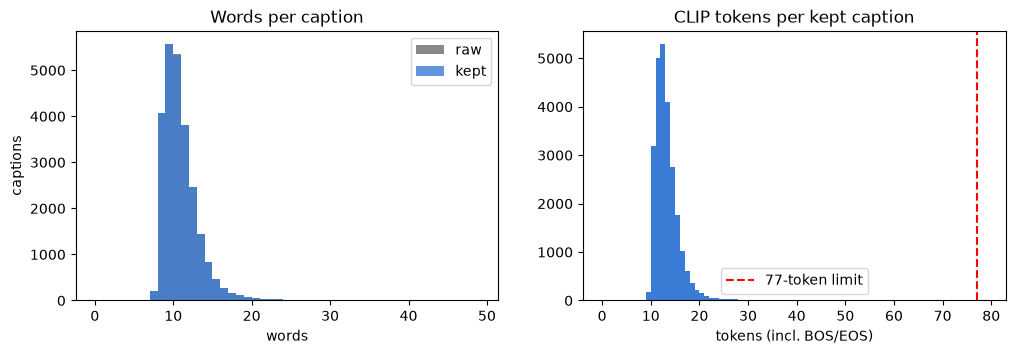

saved -> outputs/hemanth/caption_lengths.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(pairs_raw["n_words"], bins=range(0, 50), color="#888", label="raw")
axes[0].hist(pairs_clean["n_words"], bins=range(0, 50), color="#3a7bd5", alpha=0.8, label="kept")
axes[0].set(title="Words per caption", xlabel="words", ylabel="captions"); axes[0].legend()
axes[1].hist(pairs_clean["n_clip_tokens"], bins=range(0, 80), color="#3a7bd5")
axes[1].axvline(CLIP_MAX_TOKENS, color="red", ls="--", label="77-token limit")
axes[1].set(title="CLIP tokens per kept caption", xlabel="tokens (incl. BOS/EOS)"); axes[1].legend()
plt.show(); print("saved ->", save_fig(fig, "caption_lengths"))

---
## 4. Subset Curation with CLIP Scores

COCO captions vary in quality: some are vague ("a picture of something"), some describe only part of the scene.
We score every clean caption against its own image with **CLIP ViT-B/32** (cosine similarity in CLIP's shared
image–text space) and:

1. keep the **best-scoring caption** for each image (the others are kept aside as *siblings* for §9),
2. drop images whose best caption is in the **bottom 10 %** of scores (usually odd crops or captions about a detail),
3. randomly sample **2,000** of the remaining images with a fixed seed.

In [8]:
cur_model = CLIPModel.from_pretrained(CURATE_MODEL).to(DEVICE).eval()
cur_tok = CLIPTokenizer.from_pretrained(CURATE_MODEL)
cur_proc = CLIPImageProcessor.from_pretrained(CURATE_MODEL)


def load_rgb(path):
    return ImageOps.exif_transpose(Image.open(path)).convert("RGB")


@torch.no_grad()
def clip_image_embeds(model, processor, paths, desc):
    out = []
    dtype = next(model.parameters()).dtype
    for i in tqdm(range(0, len(paths), IMG_BATCH), desc=desc):
        px = processor(images=[load_rgb(p) for p in paths[i:i + IMG_BATCH]], return_tensors="pt")["pixel_values"]
        feats = model.visual_projection(model.vision_model(pixel_values=px.to(DEVICE, dtype)).pooler_output)
        out.append(F.normalize(feats, dim=-1).float().cpu())
    return torch.cat(out)


@torch.no_grad()
def clip_text_embeds(model, tokenizer, texts, desc):
    out = []
    for i in tqdm(range(0, len(texts), BATCH * 4), desc=desc):
        toks = tokenizer(texts[i:i + BATCH * 4], padding=True, truncation=True,
                         max_length=CLIP_MAX_TOKENS, return_tensors="pt").to(DEVICE)
        feats = model.text_projection(model.text_model(**toks).pooler_output)
        out.append(F.normalize(feats, dim=-1).float().cpu())
    return torch.cat(out)


t0 = time.time()
img_table = pairs_clean.drop_duplicates("image_id")[["image_id", "image_path"]].reset_index(drop=True)
img_emb = clip_image_embeds(cur_model, cur_proc, img_table["image_path"].tolist(), "B/32 images")
txt_emb = clip_text_embeds(cur_model, cur_tok, pairs_clean["caption"].tolist(), "B/32 captions")
row_of_image = pd.Series(range(len(img_table)), index=img_table["image_id"])
pairs_clean["clip_score_b32"] = (txt_emb * img_emb[row_of_image[pairs_clean["image_id"]].values]).sum(-1).numpy()
print(f"scored {len(pairs_clean):,} captions against {len(img_table):,} images in {time.time() - t0:.0f}s")

del cur_model, img_emb, txt_emb
free_memory()

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

B/32 images:   0%|          | 0/313 [00:00<?, ?it/s]

B/32 captions:   0%|          | 0/98 [00:00<?, ?it/s]

scored 24,989 captions against 5,000 images in 86s


In [9]:
ranked = pairs_clean.sort_values(["image_id", "clip_score_b32"], ascending=[True, False])
best = ranked.groupby("image_id").head(1).set_index("image_id")
# second-best caption of the same image = "sibling" used by the sanity check in section 9
sibling = ranked.groupby("image_id").nth(1).set_index("image_id")["caption"].rename("sibling_caption")
best = best.join(sibling, how="inner")        # requires >= 2 clean captions per image

threshold = best["clip_score_b32"].quantile(DROP_BOTTOM_FRAC)
eligible = best[best["clip_score_b32"] > threshold]
chosen_ids = rng.choice(eligible.index.values, size=N_PAIRS, replace=False)
subset = eligible.loc[np.sort(chosen_ids)].reset_index()

print(f"images with >=2 clean captions : {len(best):,}")
print(f"bottom-{DROP_BOTTOM_FRAC:.0%} score threshold     : {threshold:.3f}")
print(f"eligible images                : {len(eligible):,}")
print(f"sampled subset                 : {len(subset):,} image-caption pairs")
print(f"mean B/32 score  all clean / best-per-image / subset : "
      f"{pairs_clean['clip_score_b32'].mean():.3f} / {best['clip_score_b32'].mean():.3f} / "
      f"{subset['clip_score_b32'].mean():.3f}")

images with >=2 clean captions : 5,000
bottom-10% score threshold     : 0.293
eligible images                : 4,500
sampled subset                 : 2,000 image-caption pairs
mean B/32 score  all clean / best-per-image / subset : 0.302 / 0.328 / 0.332


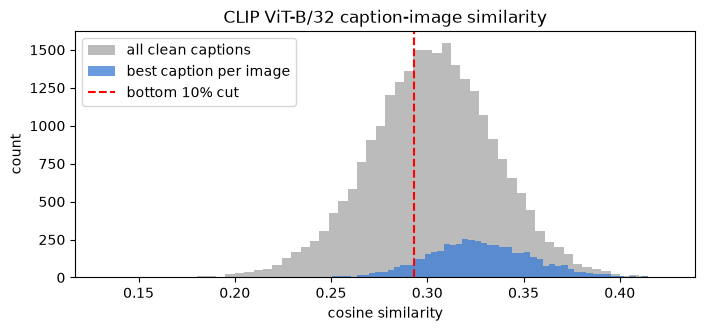

saved -> outputs/hemanth/curation_scores.png


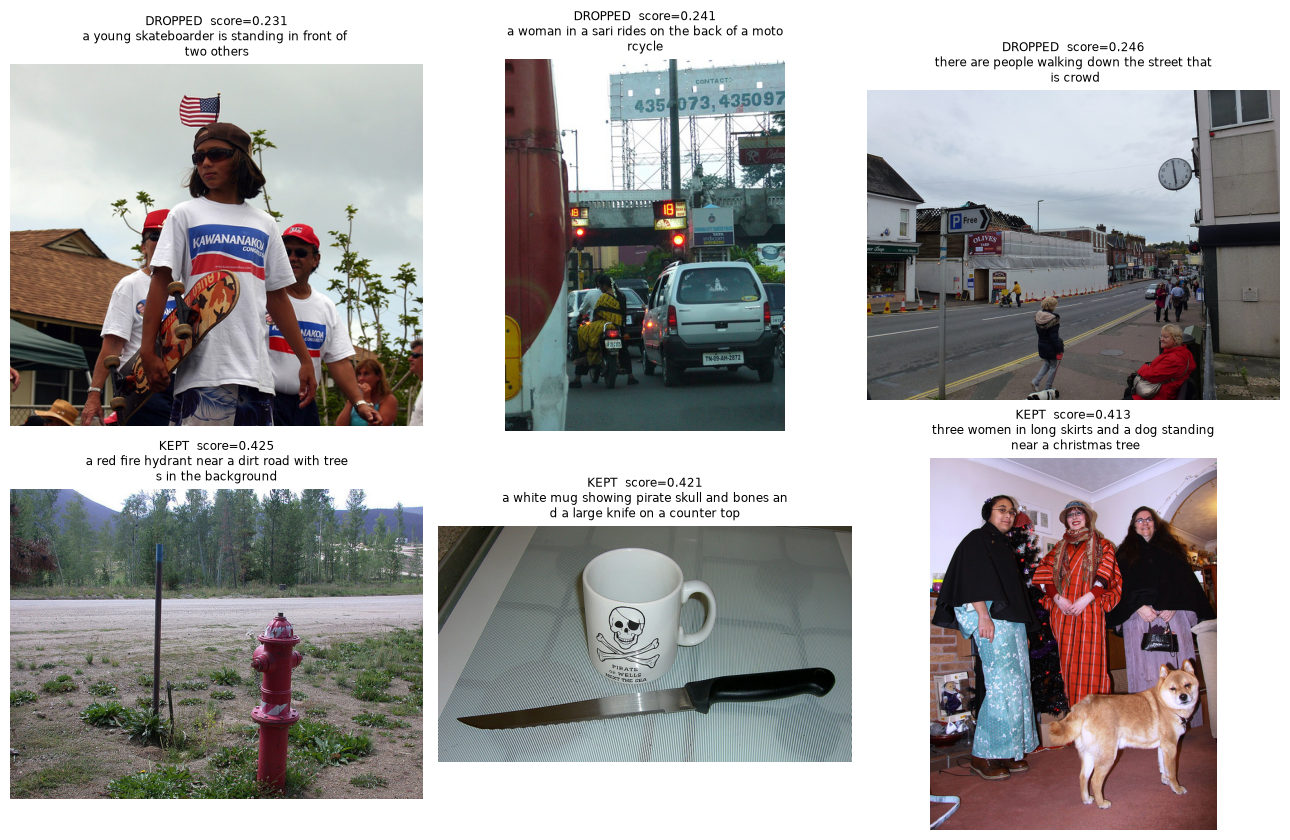

saved -> outputs/hemanth/curation_examples.png


In [10]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(pairs_clean["clip_score_b32"], bins=60, color="#bbb", label="all clean captions")
ax.hist(best["clip_score_b32"], bins=60, color="#3a7bd5", alpha=0.75, label="best caption per image")
ax.axvline(threshold, color="red", ls="--", label=f"bottom {DROP_BOTTOM_FRAC:.0%} cut")
ax.set(title="CLIP ViT-B/32 caption-image similarity", xlabel="cosine similarity", ylabel="count"); ax.legend()
plt.show(); print("saved ->", save_fig(fig, "curation_scores"))

# What the cut removes vs what it keeps
dropped = best[best["clip_score_b32"] <= threshold].sort_values("clip_score_b32").head(3)
kept = subset.sort_values("clip_score_b32", ascending=False).head(3).set_index("image_id")
fig, axes = plt.subplots(2, 3, figsize=(13, 8.5))
for row, (frame, tag) in enumerate([(dropped, "DROPPED"), (kept, "KEPT")]):
    for ax, (iid, r) in zip(axes[row], frame.iterrows()):
        ax.imshow(load_rgb(r["image_path"])); ax.axis("off")
        ax.set_title(f"{tag}  score={r['clip_score_b32']:.3f}\n" + "\n".join(
            [r["caption"][i:i + 45] for i in range(0, len(r["caption"]), 45)]), fontsize=8.5)
plt.tight_layout(); plt.show(); print("saved ->", save_fig(fig, "curation_examples"))

---
## 5. Image Preprocessing

Each image is EXIF-rotated, converted to **3-channel RGB** (COCO has some greyscale images), resized so its short
side is 512 px and **centre-cropped to 512×512** (no distortion). The 512×512 images are cached as high-quality
JPEGs; the conversion to a tensor normalised to **[-1, 1]** (what the Stable Diffusion VAE expects) happens on load
in §10, so the cache stays viewable and small.

In [11]:
def to_512(img):
    w, h = img.size
    s = IMAGE_SIZE / min(w, h)
    img = img.resize((max(IMAGE_SIZE, round(w * s)), max(IMAGE_SIZE, round(h * s))), Image.Resampling.BICUBIC)
    left, top = (img.width - IMAGE_SIZE) // 2, (img.height - IMAGE_SIZE) // 2
    return img.crop((left, top, left + IMAGE_SIZE, top + IMAGE_SIZE))


modes = {}
subset["image_512"] = ""
for i, r in tqdm(subset.iterrows(), total=len(subset), desc="resize 512"):
    dst = IMG512_DIR / f"{r['image_id']:012d}.jpg"
    if not dst.is_file():
        raw = Image.open(r["image_path"])
        modes[raw.mode] = modes.get(raw.mode, 0) + 1
        to_512(ImageOps.exif_transpose(raw).convert("RGB")).save(dst, quality=95)
    subset.at[i, "image_512"] = str(dst.relative_to(PROJECT_ROOT))

print("original colour modes (newly processed):", modes or "all cached")

# Validate the whole cache
bad = [p for p in subset["image_512"] if (im := Image.open(PROJECT_ROOT / p)).size != (IMAGE_SIZE, IMAGE_SIZE) or im.mode != "RGB"]
print(f"cached images: {len(subset):,}   not 512x512 RGB: {len(bad)}")
assert not bad

normalize = transforms.Compose([transforms.ToTensor(), transforms.Normalize([0.5] * 3, [0.5] * 3)])
x = torch.stack([normalize(Image.open(PROJECT_ROOT / p)) for p in subset["image_512"][:32]])
print(f"normalised batch: shape={tuple(x.shape)}  min={x.min():.3f}  max={x.max():.3f}  mean={x.mean():.3f}")
assert x.min() >= -1 and x.max() <= 1

resize 512:   0%|          | 0/2000 [00:00<?, ?it/s]

original colour modes (newly processed): all cached


cached images: 2,000   not 512x512 RGB: 0
normalised batch: shape=(32, 3, 512, 512)  min=-1.000  max=1.000  mean=-0.094


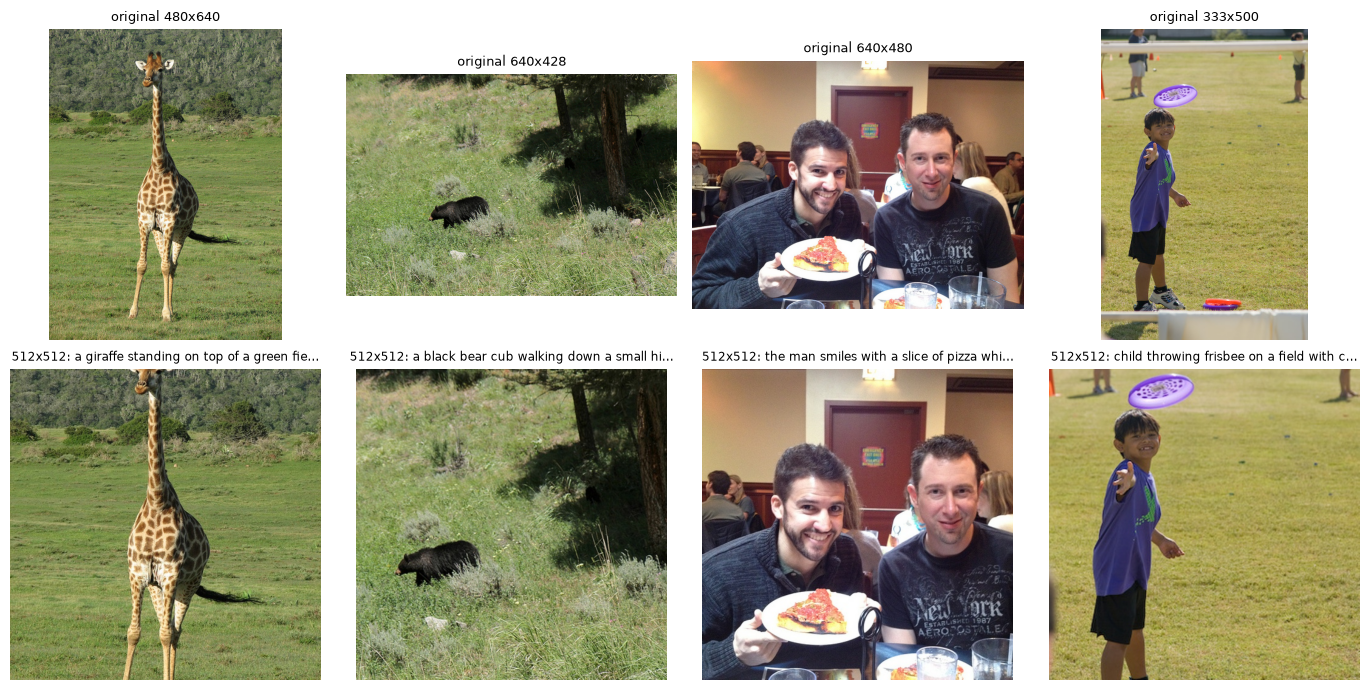

saved -> outputs/hemanth/images_before_after.png


In [12]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for k, (_, r) in enumerate(subset.sample(4, random_state=SEED).iterrows()):
    orig = load_rgb(r["image_path"])
    axes[0, k].imshow(orig); axes[0, k].set_title(f"original {orig.size[0]}x{orig.size[1]}", fontsize=9)
    axes[1, k].imshow(Image.open(PROJECT_ROOT / r["image_512"]))
    axes[1, k].set_title("512x512: " + r["caption"][:40] + ("…" if len(r["caption"]) > 40 else ""), fontsize=8.5)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout(); plt.show(); print("saved ->", save_fig(fig, "images_before_after"))

---
## 6. Text → Embedding: CLIP ViT-L/14 (Stable Diffusion's encoder)

Stable Diffusion v1.5 is conditioned on the **per-token hidden states** of `openai/clip-vit-large-patch14`'s text
encoder: a `77 × 768` tensor per prompt, padded to 77 tokens. We store three things per caption:

| Array | Shape | Use |
|---|---|---|
| `clip_seq` | 2000 × 77 × 768 (fp16) | the exact UNet conditioning input (`encoder_hidden_states`) |
| `clip_pooled` | 2000 × 768 | EOS-token summary vector |
| `clip_proj` | 2000 × 768, L2-normalised | projected into CLIP's joint image–text space, for similarity / retrieval |

The same checkpoint's vision tower is reused in §9 for retrieval, so only one CLIP-L download is needed.

In [13]:
clipL = CLIPModel.from_pretrained(SD_TEXT_MODEL, dtype=ENC_DTYPE).to(DEVICE).eval()   # fp16 on GPU, as SD runs it
print(f"text encoder: {clipL.config.text_config.num_hidden_layers} layers, hidden {clipL.config.text_config.hidden_size}, "
      f"{sum(p.numel() for p in clipL.text_model.parameters()) / 1e6:.0f}M params")

caps = subset["caption"].tolist()
seq, pooled, proj, ids = [], [], [], []
t0 = time.time()
with torch.no_grad():
    for i in tqdm(range(0, len(caps), BATCH), desc="CLIP-L text"):
        toks = clip_tok(caps[i:i + BATCH], padding="max_length", max_length=CLIP_MAX_TOKENS,
                        truncation=True, return_tensors="pt").to(DEVICE)
        out = clipL.text_model(**toks)
        seq.append(out.last_hidden_state.half().cpu())
        pooled.append(out.pooler_output.float().cpu())
        proj.append(F.normalize(clipL.text_projection(out.pooler_output), dim=-1).float().cpu())
        ids.append(toks["input_ids"].int().cpu())
clip_seq, clip_pooled = torch.cat(seq).numpy(), torch.cat(pooled).numpy()
clip_proj, clip_ids = torch.cat(proj).numpy(), torch.cat(ids).numpy()
del seq, pooled, proj, ids
print(f"encoded {len(caps):,} captions in {time.time() - t0:.1f}s on {DEVICE}")
print(f"clip_seq {clip_seq.shape} {clip_seq.dtype} ({clip_seq.nbytes / 1024**2:.0f} MB) | "
      f"clip_pooled {clip_pooled.shape} | clip_proj {clip_proj.shape} | input_ids {clip_ids.shape}")

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

text encoder: 12 layers, hidden 768, 123M params


CLIP-L text:   0%|          | 0/32 [00:00<?, ?it/s]

encoded 2,000 captions in 14.0s on mps
clip_seq (2000, 77, 768) float16 (226 MB) | clip_pooled (2000, 768) | clip_proj (2000, 768) | input_ids (2000, 77)


In [14]:
# Determinism: re-encoding a batch must reproduce the stored tensors (fp16 rounding aside),
# so later milestones can recompute instead of storing if disk is tight.
with torch.no_grad():
    toks = clip_tok(caps[:8], padding="max_length", max_length=CLIP_MAX_TOKENS, return_tensors="pt").to(DEVICE)
    again = clipL.text_model(**toks).last_hidden_state.half().cpu().numpy()
print("max abs diff on re-encode:", float(np.abs(again.astype(np.float32) - clip_seq[:8].astype(np.float32)).max()))

n_real = (clip_ids != clip_tok.pad_token_id).sum(1) if clip_tok.pad_token_id != clip_tok.eos_token_id else \
    (np.argmax(clip_ids == clip_tok.eos_token_id, axis=1) + 1)
print(f"real tokens per caption (incl. BOS/EOS): mean {n_real.mean():.1f}, max {n_real.max()} of {CLIP_MAX_TOKENS} "
      f"-> {(n_real >= CLIP_MAX_TOKENS).sum()} captions truncated")

max abs diff on re-encode: 0.0
real tokens per caption (incl. BOS/EOS): mean 13.5, max 35 of 77 -> 0 captions truncated


---
## 7. Text → Embedding: BERT-base (comparison)

BERT is a text-only Transformer trained with masked language modelling — it never saw images. We store the
`[CLS]` vector and the attention-masked **mean** of the last hidden layer (mean pooling is usually the stronger
sentence representation for un-fine-tuned BERT). Comparing it to CLIP in §9 shows what image–text pre-training buys.

In [15]:
bert_tok = AutoTokenizer.from_pretrained(BERT_MODEL)
bert = AutoModel.from_pretrained(BERT_MODEL, dtype=ENC_DTYPE).to(DEVICE).eval()


@torch.no_grad()
def bert_embed(texts, desc="BERT"):
    cls_out, mean_out = [], []
    for i in tqdm(range(0, len(texts), BATCH), desc=desc):
        toks = bert_tok(texts[i:i + BATCH], padding=True, truncation=True,
                        max_length=BERT_MAX_TOKENS, return_tensors="pt").to(DEVICE)
        h = bert(**toks).last_hidden_state
        m = toks["attention_mask"].unsqueeze(-1).to(h.dtype)
        cls_out.append(h[:, 0].float().cpu())
        mean_out.append(((h * m).sum(1) / m.sum(1)).float().cpu())
    return torch.cat(cls_out).numpy(), torch.cat(mean_out).numpy()


t0 = time.time()
bert_cls, bert_mean = bert_embed(caps)
sibs = subset["sibling_caption"].tolist()
_, sib_bert = bert_embed(sibs, "BERT siblings")   # used in section 9
del bert
free_memory()                                          # BERT is done; free it before the CLIP-L image pass
print(f"encoded {len(caps):,} captions in {time.time() - t0:.1f}s | bert_cls {bert_cls.shape} | bert_mean {bert_mean.shape}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BERT:   0%|          | 0/32 [00:00<?, ?it/s]

BERT siblings:   0%|          | 0/32 [00:00<?, ?it/s]

encoded 2,000 captions in 10.3s | bert_cls (2000, 768) | bert_mean (2000, 768)


---
## 8. Storage

The manifest (`pairs.parquet`) and every embedding array share the same row order, so row *i* of any `.npy`
file belongs to row *i* of the manifest. `metadata.json` records models, versions, filters and seed.

In [16]:
manifest = subset[["image_id", "caption_id", "file_name", "image_512", "caption", "raw_caption",
                   "sibling_caption", "clip_score_b32", "n_words", "n_clip_tokens", "width", "height"]].copy()
manifest.insert(0, "row", np.arange(len(manifest)))
manifest.to_parquet(PROC_DIR / "pairs.parquet", index=False)
manifest.to_csv(PROC_DIR / "pairs.csv", index=False)

arrays = {"clip_seq": clip_seq, "clip_pooled": clip_pooled, "clip_proj": clip_proj,
          "clip_input_ids": clip_ids, "bert_cls": bert_cls, "bert_mean": bert_mean}
for name, arr in arrays.items():
    assert len(arr) == len(manifest), name
    np.save(EMB_DIR / f"{name}.npy", arr)

metadata = {
    "dataset": "COCO 2017 captions, val split",
    "n_pairs": len(manifest), "image_size": IMAGE_SIZE, "pixel_range_on_load": [-1, 1], "seed": SEED,
    "filters": {"min_words": MIN_WORDS, "max_words": MAX_WORDS, "max_clip_tokens": CLIP_MAX_TOKENS,
                "drop_bottom_frac": DROP_BOTTOM_FRAC, "score_threshold": round(float(threshold), 4)},
    "filter_stages": filter_table.to_dict(orient="records"),
    "models": {"curation": CURATE_MODEL, "clip_text": SD_TEXT_MODEL, "bert": BERT_MODEL},
    "arrays": {k: {"shape": list(v.shape), "dtype": str(v.dtype)} for k, v in arrays.items()},
    "versions": VERSIONS,
}
(PROC_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2, default=int))

# Round-trip check
m2 = pd.read_parquet(PROC_DIR / "pairs.parquet")
assert m2["caption"].tolist() == manifest["caption"].tolist()
for name, arr in arrays.items():
    assert np.array_equal(np.load(EMB_DIR / f"{name}.npy"), arr), name
total = sum(p.stat().st_size for p in PROC_DIR.rglob("*") if p.is_file())
print(f"wrote manifest + {len(arrays)} arrays + metadata ({total / 1024**2:.0f} MB incl. image cache); round-trip OK")
for p in sorted(PROC_DIR.glob("*.*")) + sorted(EMB_DIR.glob("*.npy")):
    print(f"  {str(p.relative_to(PROJECT_ROOT)):<55} {p.stat().st_size / 1024**2:8.1f} MB")

wrote manifest + 6 arrays + metadata (461 MB incl. image cache); round-trip OK
  data/processed/hemanth/metadata.json                         0.0 MB
  data/processed/hemanth/pairs.csv                             0.5 MB
  data/processed/hemanth/pairs.parquet                         0.3 MB
  data/processed/hemanth/embeddings/bert_cls.npy               5.9 MB
  data/processed/hemanth/embeddings/bert_mean.npy              5.9 MB
  data/processed/hemanth/embeddings/clip_input_ids.npy         0.6 MB
  data/processed/hemanth/embeddings/clip_pooled.npy            5.9 MB
  data/processed/hemanth/embeddings/clip_proj.npy              5.9 MB
  data/processed/hemanth/embeddings/clip_seq.npy             225.6 MB


---
## 9. Sanity Checks

1. **Numerical health** — shapes, NaN/Inf, vector norms.
2. **Caption → image retrieval** with CLIP-L — does each caption find its own image among all 2,000? (Uses the
   ViT-L/14 vision tower, *not* the B/32 model used for curation.)
3. **Sibling vs random captions** — two human captions of the same image should be closer than two captions of
   different images, for both CLIP and BERT.
4. **Nearest neighbours** — qualitative look at what each encoder considers "similar".

In [17]:
rows = []
for name, arr in arrays.items():
    a = arr.astype(np.float32)
    norms = np.linalg.norm(a.reshape(len(a), -1), axis=1)
    rows.append({"array": name, "shape": str(arr.shape), "dtype": str(arr.dtype),
                 "nan/inf": int((~np.isfinite(a)).sum()), "mean L2 norm": "-" if name == "clip_input_ids" else round(float(norms.mean()), 3)})
    assert np.isfinite(a).all(), name
pd.DataFrame(rows)

,array,shape,dtype,nan/inf,mean L2 norm
0,clip_seq,"(2000, 77, 768)",float16,0,304.081
1,clip_pooled,"(2000, 768)",float32,0,27.802
2,clip_proj,"(2000, 768)",float32,0,1.0
3,clip_input_ids,"(2000, 77)",int32,0,-
4,bert_cls,"(2000, 768)",float32,0,14.618
5,bert_mean,"(2000, 768)",float32,0,9.733


In [18]:
img_emb_L = clip_image_embeds(clipL, CLIPImageProcessor.from_pretrained(SD_TEXT_MODEL),
                              [PROJECT_ROOT / p for p in subset["image_512"]], "CLIP-L images")
T, I = torch.from_numpy(clip_proj), img_emb_L
sim = T @ I.T                                          # [captions, images]; diagonal = correct pair
gt = torch.arange(len(T))


def recall_at(s, ks=(1, 5, 10)):
    rank = (s > s[gt, gt].unsqueeze(1)).sum(1)          # how many images beat the correct one
    return {f"R@{k}": round(float((rank < k).float().mean()) * 100, 1) for k in ks} | \
           {"median rank": int(rank.median()) + 1}


retrieval = pd.DataFrame({"caption -> image": recall_at(sim), "image -> caption": recall_at(sim.T)}).T
print(f"{len(T):,} candidates; random chance R@1 = {100 / len(T):.2f}%")
retrieval

CLIP-L images:   0%|          | 0/125 [00:00<?, ?it/s]

2,000 candidates; random chance R@1 = 0.05%


,R@1,R@5,R@10,median rank
caption -> image,64.0,87.1,93.4,1.0
image -> caption,67.9,89.6,94.8,1.0


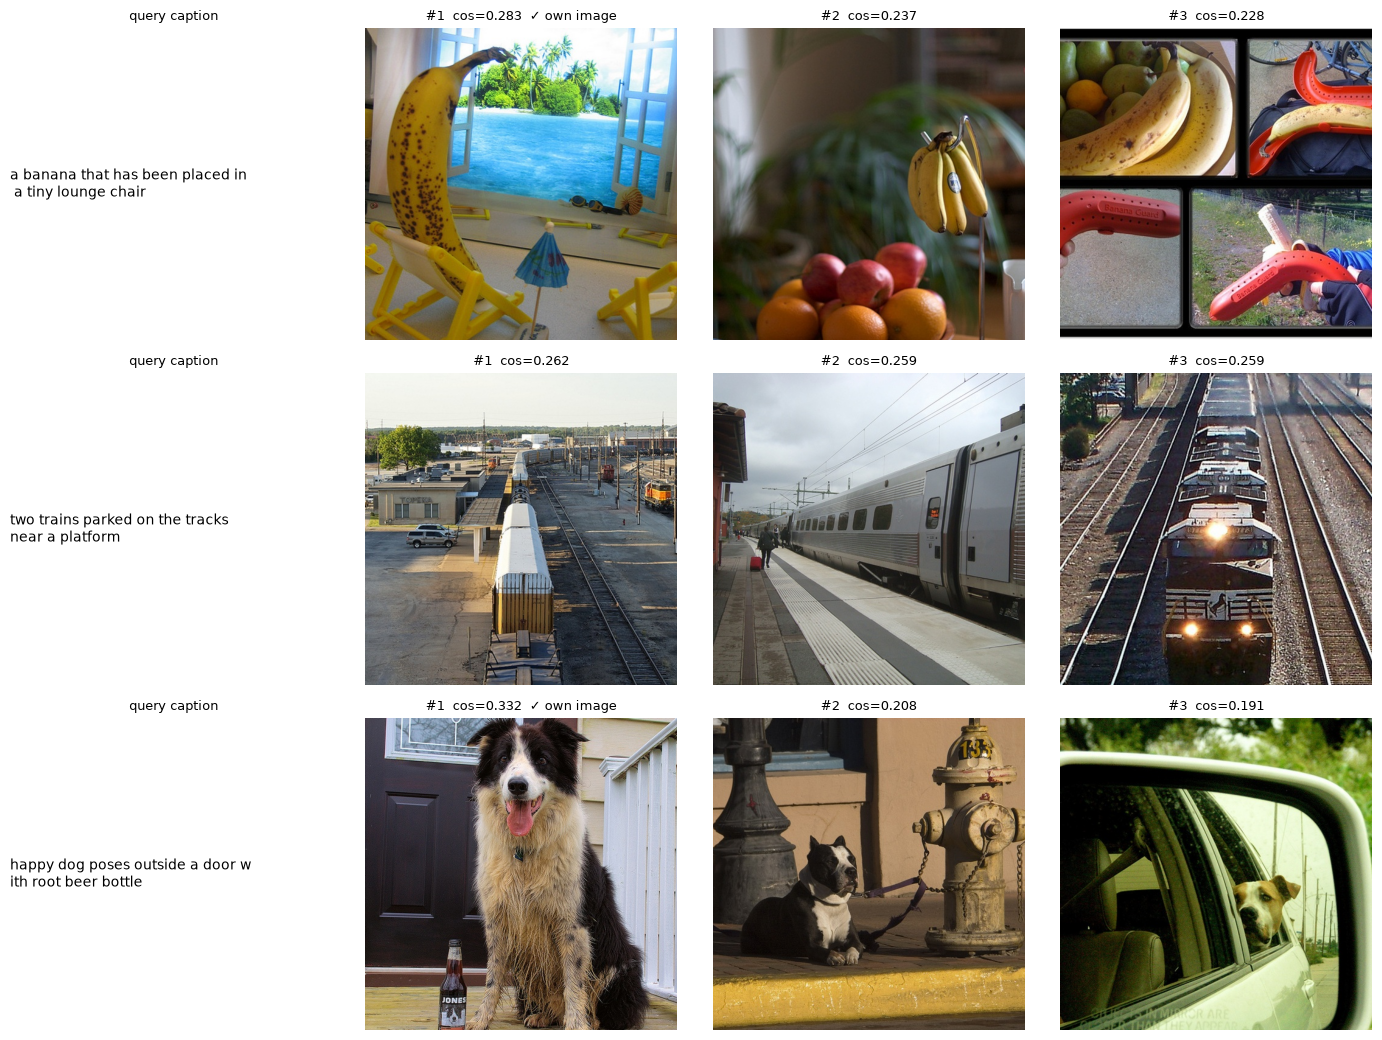

saved -> outputs/hemanth/retrieval_examples.png


In [19]:
fig, axes = plt.subplots(3, 4, figsize=(14, 10.5))
for row, qi in enumerate(rng.choice(len(subset), 3, replace=False)):
    top = sim[qi].topk(3).indices.tolist()
    axes[row, 0].text(0.0, 0.5, "\n".join([caps[qi][i:i + 32] for i in range(0, len(caps[qi]), 32)]),
                      fontsize=10, va="center"); axes[row, 0].set_title("query caption", fontsize=9)
    for k, j in enumerate(top, start=1):
        axes[row, k].imshow(Image.open(PROJECT_ROOT / subset["image_512"][j]))
        axes[row, k].set_title(f"#{k}  cos={sim[qi, j]:.3f}" + ("  ✓ own image" if j == qi else ""), fontsize=9)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout(); plt.show(); print("saved ->", save_fig(fig, "retrieval_examples"))

In [20]:
sib_clip = clip_text_embeds(clipL, clip_tok, sibs, "CLIP-L siblings").numpy()
perm = rng.permutation(len(caps))
while (perm == np.arange(len(perm))).any():        # random partner must be a different image
    perm = rng.permutation(len(caps))


def cos_rows(a, b):
    a, b = F.normalize(torch.from_numpy(a).float(), dim=-1), F.normalize(torch.from_numpy(b).float(), dim=-1)
    return (a * b).sum(-1).numpy()


results, dists = [], {}
for name, own, sib in [("CLIP-L (projected)", clip_proj, sib_clip), ("BERT (mean-pooled)", bert_mean, sib_bert)]:
    s_sib, s_rand = cos_rows(own, sib), cos_rows(own, own[perm])
    dists[name] = (s_sib, s_rand)
    results.append({"encoder": name, "sibling cos": s_sib.mean().round(3), "random cos": s_rand.mean().round(3),
                    "gap": (s_sib.mean() - s_rand.mean()).round(3),
                    "% sibling > random": round(float((s_sib > s_rand).mean()) * 100, 1)})
pd.DataFrame(results)

CLIP-L siblings:   0%|          | 0/8 [00:00<?, ?it/s]

,encoder,sibling cos,random cos,gap,% sibling > random
0,CLIP-L (projected),0.733,0.315,0.418,99.8
1,BERT (mean-pooled),0.825,0.676,0.150,95.6


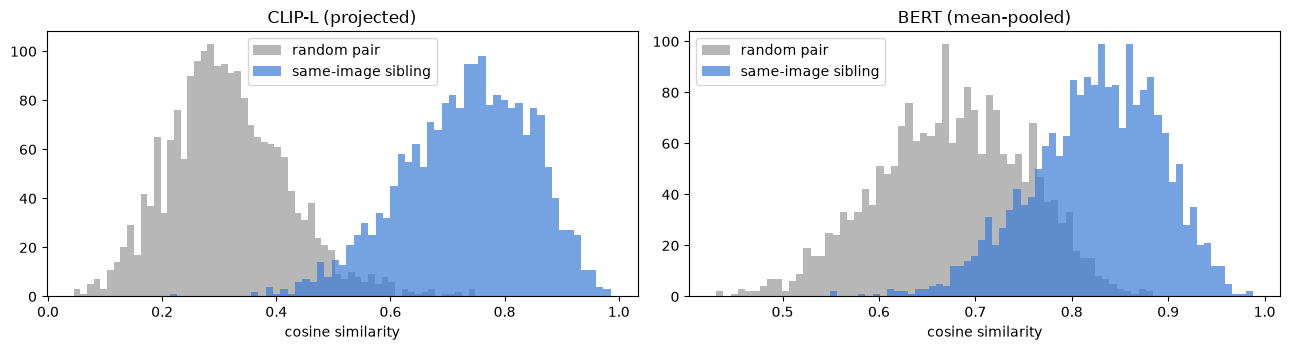

saved -> outputs/hemanth/sibling_vs_random.png


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, (name, (s_sib, s_rand)) in zip(axes, dists.items()):
    ax.hist(s_rand, bins=60, alpha=0.7, color="#999", label="random pair")
    ax.hist(s_sib, bins=60, alpha=0.7, color="#3a7bd5", label="same-image sibling")
    ax.set(title=name, xlabel="cosine similarity"); ax.legend()
plt.tight_layout(); plt.show(); print("saved ->", save_fig(fig, "sibling_vs_random"))

**Reading these numbers:** BERT's raw cosines sit in a narrow, high band (anisotropy — every sentence vector
points in roughly the same direction), so its absolute values look "similar" even for unrelated captions. What
matters is the **separation** between sibling and random pairs (`% sibling > random`). CLIP's contrastive
image–text training spreads captions out by visual content, which is exactly the property Stable Diffusion
conditioning relies on.

In [22]:
def neighbours(emb, q, k=3):
    e = F.normalize(torch.from_numpy(emb).float(), dim=-1)
    s = e @ e[q]
    s[q] = -1
    return [(caps[j], round(float(s[j]), 3)) for j in s.topk(k).indices.tolist()]


for q in rng.choice(len(caps), 3, replace=False):
    print(f"QUERY: {caps[q]}")
    for name, emb in [("CLIP", clip_proj), ("BERT", bert_mean)]:
        for c, s in neighbours(emb, q):
            print(f"   {name}  {s:.3f}  {c}")
    print()

QUERY: a male tennis player in action on the court
   CLIP  0.910  a tennis player is serving the ball to his opponent
   CLIP  0.903  a male tennis player preparing to strike the incoming ball
   CLIP  0.892  a tennis player prepares to serve the ball
   BERT  0.838  two women playing tennis at a professional court
   BERT  0.834  a female tennis player on grass about to serve
   BERT  0.827  a tennis player with a racket on a court

QUERY: a plane flying in the sky with a trail of white smoke behind it
   CLIP  0.696  a man flying a small plane in the clear weather
   CLIP  0.681  a flying airplane being viewed through power lines
   CLIP  0.667  a jet fighter flying through the sky above a snow covered mountain
   BERT  0.855  a large passenger jet flying through a gray sky
   BERT  0.853  a jet fighter flying through the sky above a snow covered mountain
   BERT  0.848  a jetliner wing flying over the top of a parking

QUERY: a white toilet in a black counter bathroom
   CLIP  0.81

---
## 10. Training-Ready `Dataset` for Milestone 2

Everything above, wrapped so later notebooks can do `DataLoader(CocoT2IDataset(...))` and get image tensors in
**[-1, 1]** plus the matching **77 × 768** CLIP conditioning — the two inputs a Stable Diffusion fine-tuning loop
needs.

In [23]:
class CocoT2IDataset(torch.utils.data.Dataset):
    def __init__(self, proc_dir=PROC_DIR, root=PROJECT_ROOT):
        self.root = Path(root)
        self.pairs = pd.read_parquet(Path(proc_dir) / "pairs.parquet")
        self.clip_seq = np.load(Path(proc_dir) / "embeddings" / "clip_seq.npy", mmap_mode="r")
        self.tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize([0.5] * 3, [0.5] * 3)])

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, i):
        r = self.pairs.iloc[i]
        return {
            "pixel_values": self.tf(Image.open(self.root / r["image_512"]).convert("RGB")),
            "encoder_hidden_states": torch.from_numpy(np.array(self.clip_seq[i], dtype=np.float32)),
            "caption": r["caption"],
            "image_id": int(r["image_id"]),
        }


ds = CocoT2IDataset()
batch = next(iter(torch.utils.data.DataLoader(ds, batch_size=8, shuffle=True,
                                              generator=torch.Generator().manual_seed(SEED))))
print(f"dataset size          : {len(ds):,}")
print(f"pixel_values          : {tuple(batch['pixel_values'].shape)}  range [{batch['pixel_values'].min():.2f}, "
      f"{batch['pixel_values'].max():.2f}]")
print(f"encoder_hidden_states : {tuple(batch['encoder_hidden_states'].shape)}  {batch['encoder_hidden_states'].dtype}")
print(f"example caption       : {batch['caption'][0]}")

dataset size          : 2,000
pixel_values          : (8, 3, 512, 512)  range [-1.00, 1.00]
encoder_hidden_states : (8, 77, 768)  torch.float32
example caption       : a young redheaded woman in sunglasses and black tank top holds a black leather purse and a white umbrella


---
## 11. Summary

In [24]:
summary = {
    "COCO val captions loaded": f"{len(pairs_raw):,}",
    "clean captions after filters": f"{len(pairs_clean):,}",
    "curated image-caption pairs": f"{len(manifest):,}",
    "image tensors": f"{IMAGE_SIZE}x{IMAGE_SIZE} RGB, [-1, 1]",
    "CLIP conditioning": str(clip_seq.shape),
    "CLIP joint-space / BERT vectors": f"{clip_proj.shape} / {bert_mean.shape}",
    "caption->image R@1 / R@5 (CLIP-L, 2k)": f"{retrieval.loc['caption -> image', 'R@1']}% / "
                                              f"{retrieval.loc['caption -> image', 'R@5']}%",
    "sibling>random  CLIP / BERT": f"{results[0]['% sibling > random']}% / {results[1]['% sibling > random']}%",
    "device": str(DEVICE),
}
(OUT_DIR / "summary.json").write_text(json.dumps(summary, indent=2))
pd.Series(summary).to_frame("value")

,value
COCO val captions loaded,"25,014"
clean captions after filters,"24,989"
curated image-caption pairs,"2,000"
image tensors,"512x512 RGB, [-1, 1]"
CLIP conditioning,"(2000, 77, 768)"
CLIP joint-space / BERT vectors,"(2000, 768) / (2000, 768)"
"caption->image R@1 / R@5 (CLIP-L, 2k)",64.0% / 87.1%
sibling>random CLIP / BERT,99.8% / 95.6%
device,mps


### Next steps (Milestone 2)

- Use `CocoT2IDataset` to feed the Stable Diffusion v1.5 UNet with `encoder_hidden_states` and VAE-encoded
  `pixel_values`; start with prompt → image generation on the 2,000 curated captions and score outputs with
  CLIP-L (the vision tower is already loaded here).
- Compare conditioning on CLIP vs. a learned projection of BERT embeddings — §9 gives the baseline separation
  each encoder starts from.
- Revisit the curation threshold: the bottom-10 % cut is a heuristic; FID/CLIP-score on generations will show
  whether stricter curation helps.